# Analyse de la satisfaction client avec l'entrepôt

**Objectif :** répondre aux questions du tableau de bord (BSC) avec des graphiques simples.

Ce notebook ne lit que le **datamart** : `fct_orders`, `dim_customers` et `dim_date`.
Pas de nettoyage ici : tout ce travail est déjà fait par dbt. Chaque graphique sort d'une requête courte en étoile.

**Période d'analyse :** janvier 2017 à août 2018 (les mois complets, voir le notebook 01).

**Avant de commencer :** lancer `dbt build` depuis `ctc_olist/`.
**Avant un nouveau `dbt build` :** redémarrer le noyau du notebook.

## Préparation

In [23]:
import duckdb

# Base construite par dbt, ouverte en lecture seule
con = duckdb.connect("../ctc_olist/ctc_olist.duckdb", read_only=True)

def sql(query):
    """Exécute une requête et renvoie le résultat sous forme de tableau."""
    return con.sql(query).df()

## 1. Le chiffre d'affaires par mois

**KPI :** `total_revenue` (perspective financière du BSC).
**Question :** comment évoluent les ventes sur la période ?

<Axes: title={'left': "Chiffre d'affaires par mois (millions de BRL)"}, xlabel='year_month'>

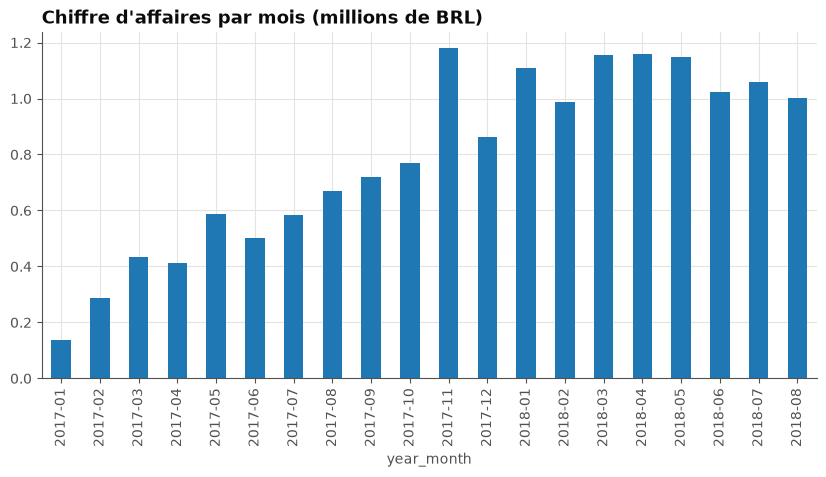

In [24]:
# Chiffre d'affaires par mois, en millions de BRL (fait + dimension date)
revenue = sql("""
    select
        strftime(dim_date.date_day, '%Y-%m')     as year_month,
        sum(fct_orders.order_amount) / 1e6       as revenue_m
    from fct_orders
    inner join dim_date on fct_orders.purchase_date_sk = dim_date.date_sk
    where dim_date.date_day between '2017-01-01' and '2018-08-31'
    group by year_month
    order by year_month
""")

revenue.plot.bar(x="year_month", y="revenue_m", legend=False, title="Chiffre d'affaires par mois (millions de BRL)")

**À retenir :**
- Les ventes **montent toute l'année 2017**, de 0,14 M en janvier à plus de 0,7 M en octobre.
- **Pic en novembre 2017** (1,18 M) : le Black Friday.
- En 2018, les ventes se **stabilisent** autour de 1 à 1,16 M par mois.

## 2. Le retard et la note, mois par mois

**KPI :** `late_delivery_rate` (perspective processus internes) et `average_review_score` (perspective client).
**Question :** quand les retards augmentent, la note baisse-t-elle ?

<Axes: title={'left': 'Commandes livrées en retard (%)'}, xlabel='year_month'>

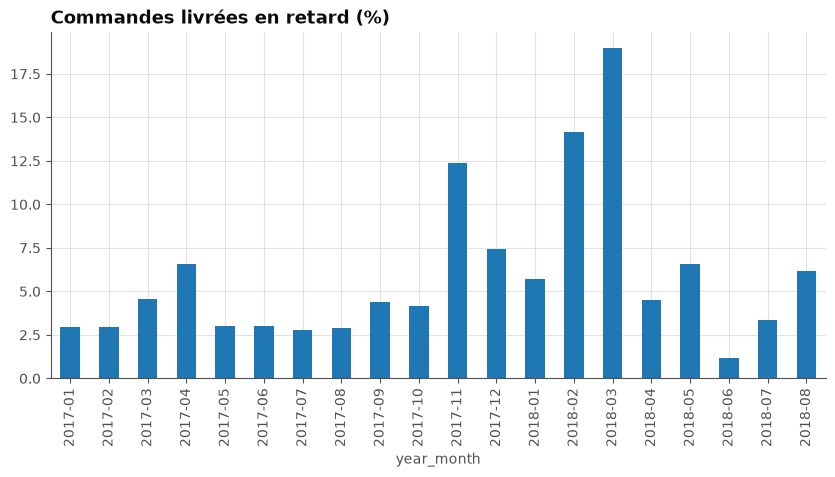

In [25]:
# Taux de retard (en %) et note moyenne par mois
monthly = sql("""
    select
        strftime(dim_date.date_day, '%Y-%m')                as year_month,
        100.0 * count(*) filter (where fct_orders.is_late)
              / count(fct_orders.delivery_days)             as late_pct,
        avg(fct_orders.review_score)                        as avg_review_score
    from fct_orders
    inner join dim_date on fct_orders.purchase_date_sk = dim_date.date_sk
    where dim_date.date_day between '2017-01-01' and '2018-08-31'
    group by year_month
    order by year_month
""")

monthly.plot.bar(x="year_month", y="late_pct", legend=False, title="Commandes livrées en retard (%)")

<Axes: title={'left': 'Note moyenne des avis (sur 5)'}, xlabel='year_month'>

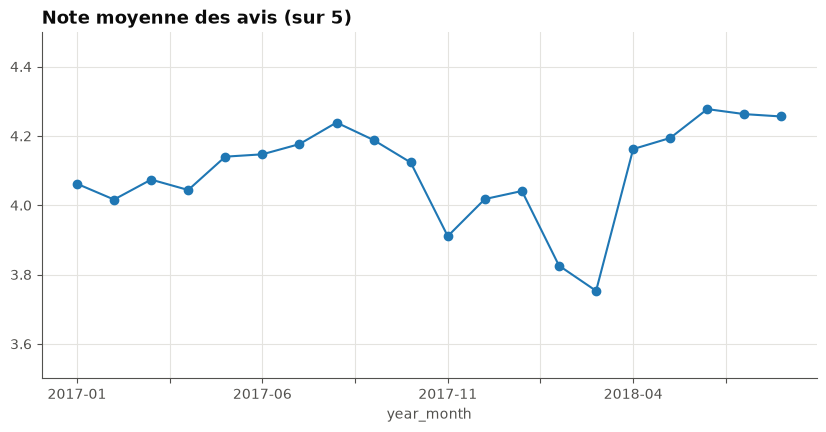

In [26]:
monthly.plot(x="year_month", y="avg_review_score", marker="o", legend=False, ylim=(3.5, 4.5), title="Note moyenne des avis (sur 5)")

**À retenir :**
- Les retards montent deux fois : **novembre 2017** (12 %, après le Black Friday) et **février-mars 2018** (14 % puis **19 %**).
- Chaque fois, la note **baisse** au même moment : 3,91 en novembre 2017, **3,75** en mars 2018.
- Quand le retard retombe (avril à août 2018), la note remonte au-dessus de 4,15.

La note est tracée en courbe, avec un axe qui commence à 3,5 : sur 5, un écart de 0,4 point est déjà important. (Des barres coupées à 3,5 exagéreraient la baisse.)

## 3. La note selon la livraison : à temps ou en retard

**KPI :** `average_review_score` (perspective client), comparé selon `is_late`.
**Question :** de combien la note baisse-t-elle quand la commande arrive en retard ?

<Axes: title={'left': 'Note moyenne selon la livraison (sur 5)'}, xlabel='delivery'>

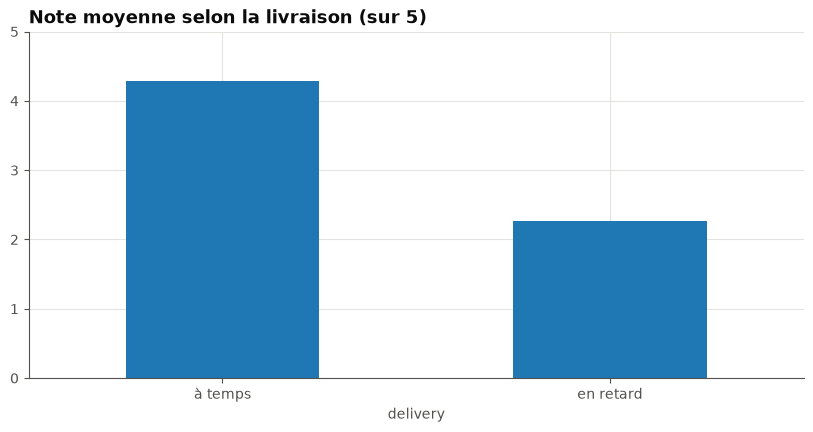

In [27]:
# Note moyenne des commandes livrées, à temps ou en retard
delivery = sql("""
    select
        case when is_late then 'en retard' else 'à temps' end as delivery,
        count(*)                                              as orders,
        avg(review_score)                                     as avg_review_score
    from fct_orders
    where delivery_days is not null
    group by delivery
    order by delivery desc   -- « à temps » d'abord
""")

delivery.plot.bar(x="delivery", y="avg_review_score", legend=False, rot=0, ylim=(0, 5), title="Note moyenne selon la livraison (sur 5)")

**À retenir :**
- Livrées **à temps** (89 941 commandes) : note moyenne de **4,29**.
- Livrées **en retard** (6 535 commandes) : note moyenne de **2,27**, soit **2 points de moins**.
- Le retard de livraison est fortement lié à une mauvaise note : c'est le message principal pour le BSC.

Ici, l'axe va de 0 à 5 (toute l'échelle des notes) : l'écart est assez grand pour se voir sans zoom.

## 4. Le taux de retard par état

**KPI :** `late_delivery_rate` (perspective processus internes), par état du client.
**Question :** où livre-t-on le plus en retard ?

<Axes: title={'left': 'Commandes livrées en retard par état (%)'}, ylabel='state'>

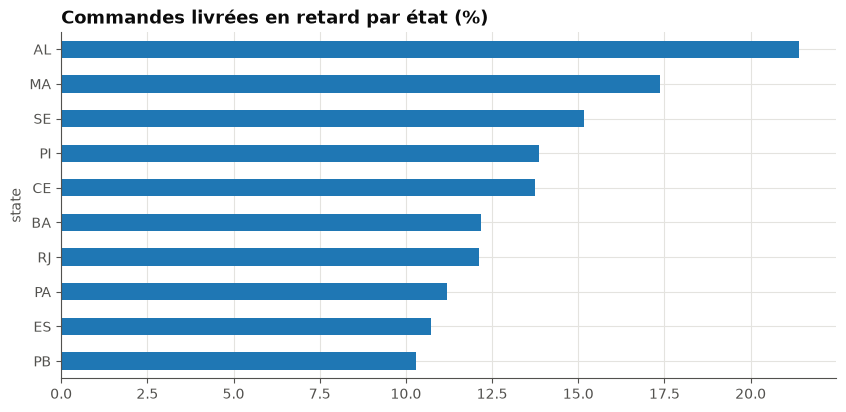

In [28]:
# Les 10 états avec le plus fort taux de retard (fait + dimension client)
states = sql("""
    with by_state as (
        select
            dim_customers.state,
            count(*)                                            as orders,
            100.0 * count(*) filter (where fct_orders.is_late)
                  / count(fct_orders.delivery_days)             as late_pct
        from fct_orders
        inner join dim_customers on fct_orders.customer_sk = dim_customers.customer_sk
        group by dim_customers.state
        having count(*) >= 100        -- assez de commandes pour un taux fiable
        order by late_pct desc
        limit 10
    )
    select * from by_state
    order by late_pct                 -- barres horizontales : le plus fort en haut
""")

states.plot.barh(x="state", y="late_pct", legend=False, title="Commandes livrées en retard par état (%)")

**À retenir :**
- Les états du **Nordeste** sont en tête : AL (**21 %**), MA (17 %), SE (15 %), PI et CE (14 %).
- **RJ** (Rio de Janeiro) a 12 % de retard sur **12 854 commandes** : c'est l'état où le retard touche le plus de clients.
- En comparaison, la moyenne nationale est de **6,8 %**, et SP (São Paulo, 41 752 commandes) est à 4,5 %.

Les états de moins de 100 commandes sont exclus (par exemple RR, 46 commandes) : sur si peu de commandes, quelques retards suffisent à faire varier le taux.

## 5. Le sentiment des commentaires

**KPI :** `negative_sentiment_rate` (perspective client).
**Questions :** le sentiment calculé à partir du texte est-il fiable ? Et que disent les clients livrés en retard ?

### 5.1 Le sentiment suit-il la note ?

<Axes: title={'left': 'Note moyenne selon le sentiment du commentaire (sur 5)'}, xlabel='sentiment_label'>

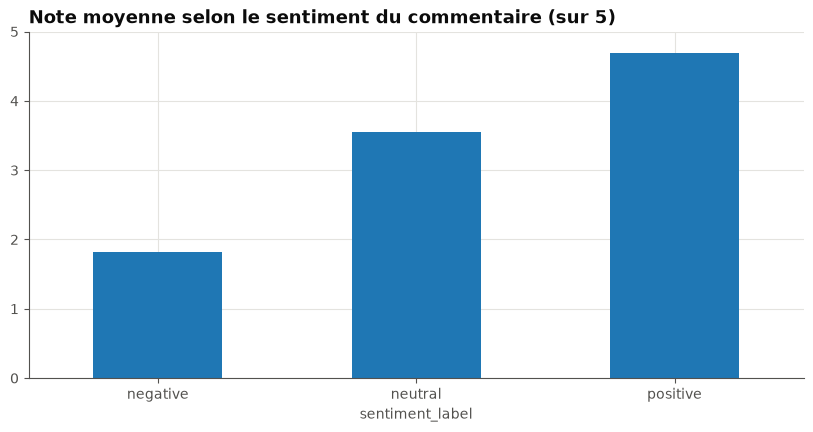

In [29]:
# Note moyenne selon le sentiment du commentaire
sentiment = sql("""
    select
        sentiment_label,
        count(*)          as orders,
        avg(review_score) as avg_review_score
    from fct_orders
    where sentiment_label is not null
    group by sentiment_label
    order by avg_review_score
""")

sentiment.plot.bar(x="sentiment_label", y="avg_review_score", legend=False, rot=0, ylim=(0, 5), title="Note moyenne selon le sentiment du commentaire (sur 5)")

**À retenir :** le sentiment suit bien la note : **1,82** pour les commentaires négatifs, **3,55** pour les neutres, **4,69** pour les positifs.
Le lexique de 58 mots transforme donc correctement le texte libre (donnée non structurée) en un indicateur fiable.

### 5.2 Le retard rend-il les commentaires négatifs ?

<Axes: title={'left': 'Commentaires négatifs selon la livraison (%)'}, xlabel='delivery'>

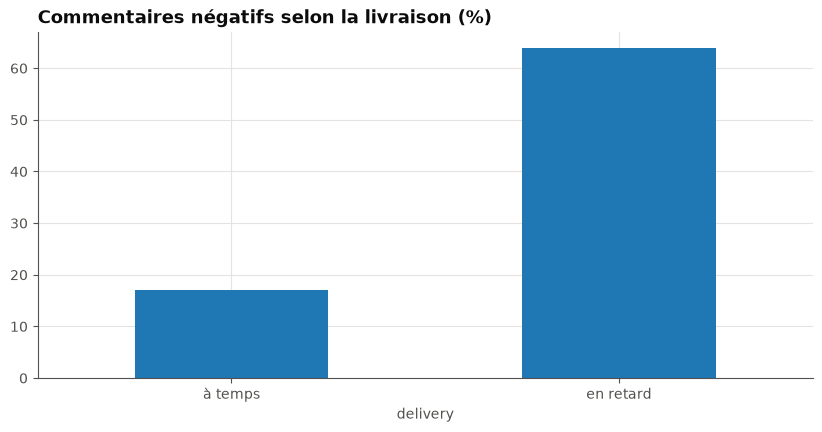

In [30]:
# Part des commentaires négatifs, livraison à temps ou en retard
negative = sql("""
    select
        case when is_late then 'en retard' else 'à temps' end    as delivery,
        100.0 * count(*) filter (where sentiment_label = 'negative')
              / count(sentiment_label)                            as negative_pct
    from fct_orders
    where delivery_days is not null
    group by delivery
    order by delivery desc   -- « à temps » d'abord
""")

negative.plot.bar(x="delivery", y="negative_pct", legend=False, rot=0, title="Commentaires négatifs selon la livraison (%)")

**À retenir :**
- Sur l'ensemble des commandes commentées, **24 %** des commentaires sont négatifs.
- Livrée **à temps** : **17 %** de commentaires négatifs. Livrée **en retard** : **64 %**.
- Le texte des clients confirme ce que montrait la note en section 3.

## Conclusion

| KPI du BSC | Perspective | Ce que montre l'entrepôt |
|---|---|---|
| `total_revenue` | financière | croissance en 2017, pic du Black Friday, puis plateau autour de 1 M BRL par mois |
| `late_delivery_rate` | processus internes | 6,8 % en moyenne, mais 19 % en mars 2018 et plus de 14 % dans le Nordeste |
| `average_review_score` | client | 4,29 à temps contre 2,27 en retard |
| `negative_sentiment_rate` | client | 17 % à temps contre 64 % en retard |

**Le message pour le BSC :** la **ponctualité de la livraison** est le point d'action principal. Quand le retard monte, la note baisse et les commentaires deviennent négatifs.

Chaque graphique vient d'une requête courte sur le datamart : c'est le rôle de l'entrepôt de rendre ces analyses simples.

In [31]:
# Fermer la connexion (à faire avant un dbt build)
con.close()